In this notebook we check two things. First, how much extra sales a promotion really brings (promotion lift). Second, whether sales of one family go down when another family is on promotion (cannibalization). We only use data from 15 July 2015, because older records are not reliable.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

fig_folder = '../outputs/figures_promo'
table_folder = '../outputs/tables'
os.makedirs(fig_folder, exist_ok=True)
os.makedirs(table_folder, exist_ok=True)

pre_days = 7
max_run = 7
min_stores = 5
min_sales = 1
first_date = '2015-07-15'

We load only the columns we need from the cleaned dataset: date, store, family, sales and onpromotion.

In [2]:
# load data
columns = ['date', 'store_nbr', 'family', 'sales', 'onpromotion']

try:
    df = pd.read_parquet('../data/processed/features_engineered.parquet', columns=columns)
    source = 'features_engineered.parquet'
except Exception as e:
    print('could not read the parquet file:', e)
    df = pd.read_csv('../data/raw/train.csv', usecols=columns)
    source = 'raw train.csv'

print('loaded from:', source)

if str(df['date'].dtype).startswith('int'):
    df['date'] = pd.to_datetime(df['date'], unit='ms')
else:
    df['date'] = pd.to_datetime(df['date'])
df['family'] = df['family'].astype(str)
df['store_nbr'] = df['store_nbr'].astype(int)

df = df[df['date'] >= first_date]

print('rows:', len(df))
print('dates:', df['date'].min().date(), 'to', df['date'].max().date())
print('stores:', df['store_nbr'].nunique(), '| families:', df['family'].nunique())
df.head()

loaded from: features_engineered.parquet
rows: 1356102
dates: 2015-07-15 to 2017-08-15
stores: 54 | families: 33


,date,store_nbr,family,sales,onpromotion
923,2015-07-15,1,AUTOMOTIVE,4.0,0
924,2015-07-16,1,AUTOMOTIVE,2.0,0
925,2015-07-17,1,AUTOMOTIVE,1.0,0
926,2015-07-18,1,AUTOMOTIVE,1.0,0
927,2015-07-19,1,AUTOMOTIVE,0.0,0


For each family we make a table with dates as rows and stores as columns. This makes it easy to look at the days before a promotion and to compare a store with other stores on the same day.

In [3]:
families = sorted(df['family'].unique())
all_dates = pd.date_range(df['date'].min(), df['date'].max())

sales_wide = {}
promo_wide = {}

for fam in families:
    part = df[df['family'] == fam]
    sales_table = part.pivot(index='date', columns='store_nbr', values='sales')
    promo_table = part.pivot(index='date', columns='store_nbr', values='onpromotion')
    sales_wide[fam] = sales_table.reindex(all_dates)
    promo_wide[fam] = promo_table.reindex(all_dates).fillna(0)

print('tables made for', len(families), 'families')
print('shape of one table (days x stores):', sales_wide[families[0]].shape)

tables made for 33 families
shape of one table (days x stores): (763, 54)


A simple before vs during comparison is not fair, because sales also change due to weekdays, holidays and growth. So we also look at stores with no promotion on the same days, and use their change as the expected sales. Naive lift compares with the days before. Adjusted lift compares with the expected sales. For the 95% interval we resample whole weeks (bootstrap).

In [4]:
# lift function
def get_lift(events, boot=1000):
    per_week = events.groupby('week')[['post', 'pre', 'expected']].sum()
    post = per_week['post'].values
    pre = per_week['pre'].values
    expected = per_week['expected'].values
    n_weeks = len(per_week)

    naive = post.sum() / pre.sum() - 1
    adjusted = post.sum() / expected.sum() - 1

    naive_list = []
    adjusted_list = []
    for i in range(boot):
        pick = np.random.randint(0, n_weeks, n_weeks)
        naive_list.append(post[pick].sum() / pre[pick].sum() - 1)
        adjusted_list.append(post[pick].sum() / expected[pick].sum() - 1)
    naive_list = np.array(naive_list)
    adjusted_list = np.array(adjusted_list)

    p = 2 * min((adjusted_list <= 0).mean(), (adjusted_list >= 0).mean())
    if p < 1 / boot:
        p = 1 / boot

    result = {}
    result['n'] = len(events)
    result['naive_pct'] = 100 * naive
    result['naive_low'] = 100 * np.percentile(naive_list, 2.5)
    result['naive_high'] = 100 * np.percentile(naive_list, 97.5)
    result['adj_pct'] = 100 * adjusted
    result['adj_low'] = 100 * np.percentile(adjusted_list, 2.5)
    result['adj_high'] = 100 * np.percentile(adjusted_list, 97.5)
    result['p_value'] = p
    return result

def lift_by_group(events, column, min_n=40, boot=500):
    rows = []
    for name, group in events.groupby(column, observed=True):
        if len(group) < min_n:
            continue
        result = get_lift(group, boot)
        result[column] = name
        rows.append(result)
    return pd.DataFrame(rows).set_index(column)

Method A: a launch is the first day of a promotion after 7 days with no promotion. We compare the promotion days with the 7 days before, and also note how many days the promotion lasted.

In [5]:
# method A: launches
def get_launches(pre_days):
    all_events = []

    for fam in families:
        sales = sales_wide[fam]
        promo = (promo_wide[fam] > 0).astype(int)

        pre = sales.rolling(pre_days).mean().shift(1)
        pre2 = sales.rolling(pre_days).mean().shift(pre_days + 1)

        promo_before = promo.rolling(pre_days).sum().shift(1)
        start = (promo == 1) & (promo_before == 0)

        run = promo.copy()
        still_on = promo.copy()
        for j in range(1, max_run):
            still_on = still_on * promo.shift(-j, fill_value=0)
            run = run + still_on

        for k in range(1, max_run + 1):
            post = sales.rolling(k).mean().shift(-(k - 1))

            busy = promo.rolling(pre_days + k).sum().shift(-(k - 1)) > 0

            good = (pre >= min_sales) & post.notna()
            control = good & (~busy)
            n_control = control.sum(axis=1)

            growth = post.where(control).sum(axis=1) / pre.where(control).sum(axis=1)
            growth = growth.where(n_control >= min_stores)

            control2 = control & pre2.notna()
            growth2 = pre.where(control2).sum(axis=1) / pre2.where(control2).sum(axis=1)
            growth2 = growth2.where(control2.sum(axis=1) >= min_stores)

            treated = start & (run == k) & good
            rows, cols = np.where(treated.values)
            if len(rows) == 0:
                continue

            events = pd.DataFrame()
            events['date'] = sales.index[rows]
            events['store'] = sales.columns[cols]
            events['family'] = fam
            events['days'] = k
            events['post'] = post.values[rows, cols]
            events['pre'] = pre.values[rows, cols]
            events['pre2'] = pre2.values[rows, cols]
            events['growth'] = growth.values[rows]
            events['growth2'] = growth2.values[rows]
            all_events.append(events)

    events = pd.concat(all_events, ignore_index=True)
    events = events.dropna(subset=['growth'])
    events['expected'] = events['pre'] * events['growth']
    events['week'] = (events['date'] - all_dates[0]).dt.days // 7
    return events

launches = get_launches(pre_days)
print('number of launches used:', len(launches))
print()
print('launches by promotion length (days):')
print(launches['days'].value_counts().sort_index())

number of launches used: 5071

launches by promotion length (days):
days
1    3983
2     498
3     211
4      95
5      41
6      37
7     206
Name: count, dtype: int64


The naive lift is 7.5% but the adjusted lift is 4.2%. So about half of the naive lift was normal sales change, not the promotion.

In [6]:
overall_a = get_lift(launches, boot=2000)

print('launches:', overall_a['n'])
print('naive lift (before vs during only):', round(overall_a['naive_pct'], 1), '%', '| 95% CI', round(overall_a['naive_low'], 1), 'to', round(overall_a['naive_high'], 1))
print('adjusted lift (with comparison stores):', round(overall_a['adj_pct'], 1), '%', '| 95% CI', round(overall_a['adj_low'], 1), 'to', round(overall_a['adj_high'], 1), '| p =', round(overall_a['p_value'], 3))

by_days = lift_by_group(launches, 'days', min_n=30)
by_days

launches: 5071
naive lift (before vs during only): 7.5 % | 95% CI 1.7 to 15.3
adjusted lift (with comparison stores): 4.2 % | 95% CI 1.1 to 8.6 | p = 0.005


,n,naive_pct,naive_low,naive_high,adj_pct,adj_low,adj_high,p_value
days,,,,,,,,
1,3983,7.193153,1.581287,14.667378,3.461515,0.185170,8.677447,0.036
2,498,8.394847,-3.025506,20.612211,1.308088,-2.926012,7.409305,0.668
3,211,8.935852,0.988193,16.492149,2.569569,-6.983841,11.564792,0.528
4,95,4.690696,-3.424940,18.005029,9.116026,3.685141,18.150625,0.002
5,41,17.717123,1.810825,42.635394,13.883914,-2.011654,27.618076,0.088
6,37,11.737271,0.565448,33.307627,15.109533,5.438392,31.678680,0.002
7,206,6.891134,-6.329865,37.925908,16.119636,7.824517,36.356316,0.002


Figure 1: grey is naive lift and blue is adjusted lift. Short promotions give a small lift, and promotions of 4 days or more give a bigger lift.

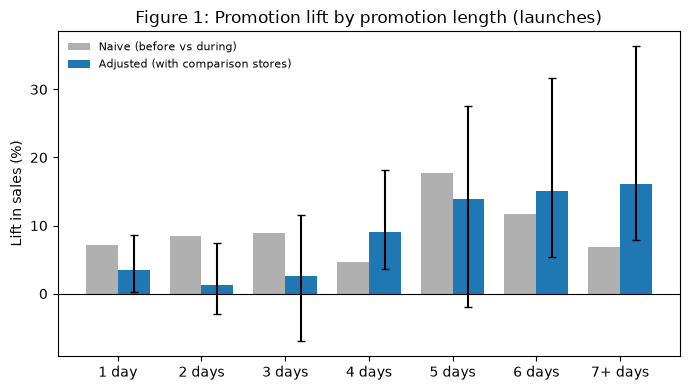

In [7]:
labels = []
for k in by_days.index:
    if k == 7:
        labels.append('7+ days')
    elif k == 1:
        labels.append('1 day')
    else:
        labels.append(str(k) + ' days')

x = np.arange(len(by_days))
width = 0.38

plt.figure(figsize=(7, 4))
plt.bar(x - width / 2, by_days['naive_pct'], width, label='Naive (before vs during)', color='#b0b0b0')
low_error = by_days['adj_pct'] - by_days['adj_low']
high_error = by_days['adj_high'] - by_days['adj_pct']
plt.bar(x + width / 2, by_days['adj_pct'], width, label='Adjusted (with comparison stores)', color='#1f77b4',
        yerr=[low_error, high_error], capsize=3)
plt.xticks(x, labels)
plt.axhline(0, color='black', linewidth=0.8)
plt.ylabel('Lift in sales (%)')
plt.title('Figure 1: Promotion lift by promotion length (launches)')
plt.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(fig_folder + '/fig1_lift_by_length.png')
plt.show()

Lift for each family separately (families with at least 60 launches).

In [8]:
by_family_a = lift_by_group(launches, 'family', min_n=60)
by_family_a = by_family_a.sort_values('adj_pct')
by_family_a[['n', 'naive_pct', 'adj_pct', 'adj_low', 'adj_high', 'p_value']].round(2)

,n,naive_pct,adj_pct,adj_low,adj_high,p_value
family,,,,,,
HOME CARE,337,-0.70,0.24,-2.67,2.81,0.93
PERSONAL CARE,204,1.36,2.22,-2.36,5.91,0.31
CELEBRATION,720,4.90,4.00,-1.89,9.76,0.18
PREPARED FOODS,75,-5.31,4.69,-3.18,13.52,0.16
FROZEN FOODS,77,16.03,5.29,-3.46,16.33,0.28
LADIESWEAR,162,4.66,6.95,0.16,15.39,0.05
HOME AND KITCHEN I,426,12.57,7.97,-2.50,17.49,0.14
PLAYERS AND ELECTRONICS,302,14.86,12.19,3.09,19.46,0.02
"LIQUOR,WINE,BEER",181,55.23,12.67,-14.56,56.90,0.72


Figure 2: green means the lift is clearly above zero, grey means not clear. SCHOOL AND OFFICE SUPPLIES and LAWN AND GARDEN look very high, but they have few launches and may be affected by season.

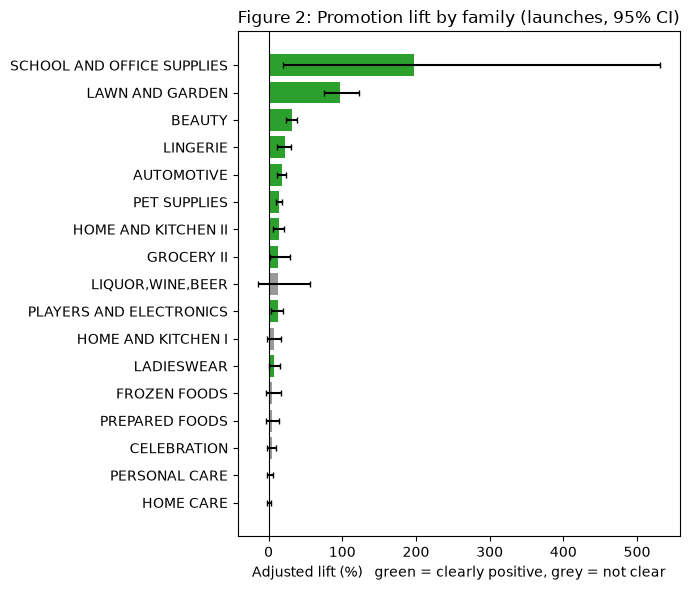

In [9]:
colors = []
for i in range(len(by_family_a)):
    if by_family_a['adj_low'].iloc[i] > 0:
        colors.append('#2ca02c')
    elif by_family_a['adj_high'].iloc[i] < 0:
        colors.append('#d62728')
    else:
        colors.append('#999999')

low_error = by_family_a['adj_pct'] - by_family_a['adj_low']
high_error = by_family_a['adj_high'] - by_family_a['adj_pct']

plt.figure(figsize=(7, 6))
plt.barh(by_family_a.index, by_family_a['adj_pct'], color=colors, xerr=[low_error, high_error], capsize=2)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Adjusted lift (%)   green = clearly positive, grey = not clear')
plt.title('Figure 2: Promotion lift by family (launches, 95% CI)')
plt.tight_layout()
plt.savefig(fig_folder + '/fig2_lift_by_family_launch.png')
plt.show()

Here we check if the method is fair. The pre-trend check runs the same method on the weeks before the promotion, so the result should be close to 0 (we get -0.7%). We also try 3 and 14 days instead of 7. The lift stays positive, but its size changes, so 4.2% depends on the 7 day choice.

In [10]:
pretrend = launches.dropna(subset=['growth2', 'pre2']).copy()
pretrend['post'] = pretrend['pre']
pretrend['pre'] = pretrend['pre2']
pretrend['expected'] = pretrend['pre2'] * pretrend['growth2']
pretrend = pretrend[pretrend['expected'] > 0]

pt = get_lift(pretrend)
print('pre-trend (should be close to 0):', round(pt['adj_pct'], 1), '%', '| 95% CI', round(pt['adj_low'], 1), 'to', round(pt['adj_high'], 1), '| n =', pt['n'])

rows = []
rows.append({'before days': pre_days, 'launches': overall_a['n'], 'naive %': overall_a['naive_pct'],
             'adjusted %': overall_a['adj_pct'], 'ci low': overall_a['adj_low'], 'ci high': overall_a['adj_high']})
for other in [3, 14]:
    other_launches = get_launches(other)
    r = get_lift(other_launches)
    rows.append({'before days': other, 'launches': r['n'], 'naive %': r['naive_pct'],
                 'adjusted %': r['adj_pct'], 'ci low': r['adj_low'], 'ci high': r['adj_high']})

sensitivity = pd.DataFrame(rows).round(2)
sensitivity

pre-trend (should be close to 0): -0.7 % | 95% CI -2.1 to 0.6 | n = 4854


,before days,launches,naive %,adjusted %,ci low,ci high
0,7,5071,7.48,4.25,1.12,8.57
1,3,22444,18.04,20.98,18.43,23.48
2,14,3282,13.78,8.18,2.26,16.27


Method B: big families like GROCERY I and BEVERAGES are on promotion almost every day, so they have almost no launches. For them we use weeks where the number of promoted items jumps a lot, and compare with stores where it stayed about the same.

In [11]:
# method B: weekly surge
week_sales = {}
week_items = {}

for fam in families:
    sales = sales_wide[fam]
    items = promo_wide[fam]
    average = sales.resample('W-SUN').mean()
    days_with_data = sales.resample('W-SUN').count()
    week_sales[fam] = average.where(days_with_data == 7)
    week_items[fam] = items.resample('W-SUN').mean()

pre_w = {}
post_w = {}
pre2_w = {}
surge = {}
stable = {}
ratio = {}

for fam in families:
    pre = week_sales[fam].shift(1)
    post = week_sales[fam]
    items_pre = week_items[fam].shift(1)
    items_post = week_items[fam]
    change = items_post - items_pre

    good = (pre >= min_sales) & post.notna()
    limit = (0.2 * items_pre).clip(lower=1)

    pre_w[fam] = pre
    post_w[fam] = post
    pre2_w[fam] = week_sales[fam].shift(2)
    surge[fam] = good & (change >= 3) & (items_post >= 1.5 * items_pre)
    stable[fam] = good & (change.abs() <= limit)
    ratio[fam] = items_post / items_pre.clip(lower=0.5)

total_surge = 0
total_stable = 0
for fam in families:
    total_surge = total_surge + surge[fam].values.sum()
    total_stable = total_stable + stable[fam].values.sum()
print('surge cases:', total_surge, '| stable cases:', total_stable)

surge cases: 3738 | stable cases: 131262


The adjusted lift in surge weeks is 3.8%, close to Method A. The pre-trend is -1.7%, a bit below zero, so part of this lift may be sales going back to normal.

In [12]:
all_events = []
for fam in families:
    control = stable[fam]
    growth = post_w[fam].where(control).sum(axis=1) / pre_w[fam].where(control).sum(axis=1)
    growth = growth.where(control.sum(axis=1) >= min_stores)

    control2 = control & pre2_w[fam].notna()
    growth2 = pre_w[fam].where(control2).sum(axis=1) / pre2_w[fam].where(control2).sum(axis=1)
    growth2 = growth2.where(control2.sum(axis=1) >= min_stores)

    rows, cols = np.where(surge[fam].values)
    if len(rows) == 0:
        continue
    events = pd.DataFrame()
    events['date'] = surge[fam].index[rows]
    events['store'] = surge[fam].columns[cols]
    events['family'] = fam
    events['post'] = post_w[fam].values[rows, cols]
    events['pre'] = pre_w[fam].values[rows, cols]
    events['pre2'] = pre2_w[fam].values[rows, cols]
    events['growth'] = growth.values[rows]
    events['growth2'] = growth2.values[rows]
    events['ratio'] = ratio[fam].values[rows, cols]
    all_events.append(events)

surges = pd.concat(all_events, ignore_index=True)
surges = surges.dropna(subset=['growth'])
surges['expected'] = surges['pre'] * surges['growth']
surges['week'] = (surges['date'] - all_dates[0]).dt.days // 7

overall_b = get_lift(surges, boot=2000)
print('surge weeks used:', overall_b['n'])
print('naive lift:', round(overall_b['naive_pct'], 1), '%', '| 95% CI', round(overall_b['naive_low'], 1), 'to', round(overall_b['naive_high'], 1))
print('adjusted lift:', round(overall_b['adj_pct'], 1), '%', '| 95% CI', round(overall_b['adj_low'], 1), 'to', round(overall_b['adj_high'], 1), '| p =', round(overall_b['p_value'], 3))

pretrend_b = surges.dropna(subset=['growth2', 'pre2']).copy()
pretrend_b['post'] = pretrend_b['pre']
pretrend_b['pre'] = pretrend_b['pre2']
pretrend_b['expected'] = pretrend_b['pre2'] * pretrend_b['growth2']
pretrend_b = pretrend_b[pretrend_b['expected'] > 0]
ptb = get_lift(pretrend_b)
print('pre-trend check (should be close to 0):', round(ptb['adj_pct'], 1), '%', '| 95% CI', round(ptb['adj_low'], 1), 'to', round(ptb['adj_high'], 1))

surge weeks used: 2682
naive lift: 3.5 % | 95% CI -0.7 to 8.3
adjusted lift: 3.8 % | 95% CI 1.6 to 6.2 | p = 0.002
pre-trend check (should be close to 0): -1.7 % | 95% CI -3.7 to 0.1


Figure 3: lift for the big families in surge weeks. Most are small, between about 2% and 7%.

                      n  naive_pct  adj_pct  adj_low  adj_high  p_value
family                                                                 
MEATS               106       7.79    -1.55   -10.61      3.87     0.65
PERSONAL CARE       216      -0.96    -0.60    -5.49      4.39     0.98
BREAD/BAKERY        211       2.14     1.91    -0.04      4.56     0.07
BEVERAGES           421       3.78     2.30    -1.06      5.88     0.18
DAIRY               331       1.42     2.66    -0.69      6.34     0.13
HOME CARE           134       8.08     4.14    -0.23      9.71     0.08
CLEANING            349       0.56     4.42     1.73      7.70     0.00
GROCERY I           456       2.63     5.01     1.42      9.19     0.00
PRODUCE              95       7.96     6.81     3.43     20.46     0.00
HOME AND KITCHEN I   72      16.48    44.73     3.17     83.37     0.00


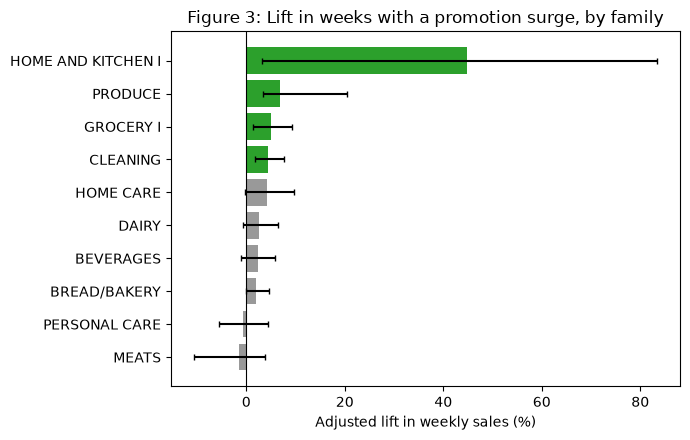

In [13]:
by_family_b = lift_by_group(surges, 'family', min_n=60)
by_family_b = by_family_b.sort_values('adj_pct')
print(by_family_b[['n', 'naive_pct', 'adj_pct', 'adj_low', 'adj_high', 'p_value']].round(2))

colors = []
for i in range(len(by_family_b)):
    if by_family_b['adj_low'].iloc[i] > 0:
        colors.append('#2ca02c')
    elif by_family_b['adj_high'].iloc[i] < 0:
        colors.append('#d62728')
    else:
        colors.append('#999999')

low_error = by_family_b['adj_pct'] - by_family_b['adj_low']
high_error = by_family_b['adj_high'] - by_family_b['adj_pct']

plt.figure(figsize=(7, 4.5))
plt.barh(by_family_b.index, by_family_b['adj_pct'], color=colors, xerr=[low_error, high_error], capsize=2)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Adjusted lift in weekly sales (%)')
plt.title('Figure 3: Lift in weeks with a promotion surge, by family')
plt.tight_layout()
plt.savefig(fig_folder + '/fig3_lift_by_family_weekly.png')
plt.show()

Figure 4: lift by how much the number of promoted items grew. There is no clear pattern, so a bigger jump does not always mean a bigger lift.

           n  naive_pct  adj_pct  adj_low  adj_high
size                                               
1.5-2x  1115       2.16     5.01     2.19      7.92
2-4x     904       4.97     2.29    -0.23      5.39
4-10x    441       2.82     1.80    -0.33      3.87
10x+     205       7.74     6.81     3.34     15.21


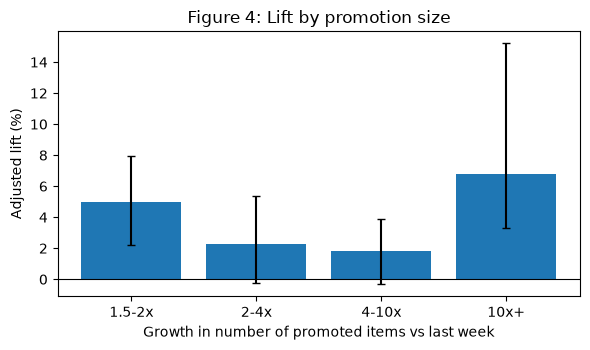

In [14]:
surges['size'] = pd.cut(surges['ratio'], [1.5, 2, 4, 10, 1000000], labels=['1.5-2x', '2-4x', '4-10x', '10x+'])
dose = lift_by_group(surges, 'size', min_n=30)
print(dose[['n', 'naive_pct', 'adj_pct', 'adj_low', 'adj_high']].round(2))

low_error = dose['adj_pct'] - dose['adj_low']
high_error = dose['adj_high'] - dose['adj_pct']

plt.figure(figsize=(6, 3.6))
plt.bar(dose.index.astype(str), dose['adj_pct'], color='#1f77b4', yerr=[low_error, high_error], capsize=3)
plt.axhline(0, color='black', linewidth=0.8)
plt.xlabel('Growth in number of promoted items vs last week')
plt.ylabel('Adjusted lift (%)')
plt.title('Figure 4: Lift by promotion size')
plt.tight_layout()
plt.savefig(fig_folder + '/fig4_dose_response.png')
plt.show()

Cannibalization: when family A has a promotion surge, do sales of family B go down? We picked pairs that can replace each other (for example BEVERAGES and LIQUOR) or are bought together (for example DAIRY and BREAD). In this data a product is a whole family, so we can only check between families.

In [15]:
# cannibalization
def get_pair_events(fam_a, fam_b):
    control = stable[fam_a] & stable[fam_b]
    pre = pre_w[fam_b]
    post = post_w[fam_b]

    growth = post.where(control).sum(axis=1) / pre.where(control).sum(axis=1)
    growth = growth.where(control.sum(axis=1) >= min_stores)

    treated = surge[fam_a] & stable[fam_b]
    rows, cols = np.where(treated.values)

    events = pd.DataFrame()
    events['date'] = treated.index[rows]
    events['post'] = post.values[rows, cols]
    events['pre'] = pre.values[rows, cols]
    events['growth'] = growth.values[rows]
    events = events.dropna(subset=['growth'])
    events['expected'] = events['pre'] * events['growth']
    events['week'] = (events['date'] - all_dates[0]).dt.days // 7
    return events

chosen = [('BEVERAGES', 'LIQUOR,WINE,BEER', 'substitute'),
          ('DAIRY', 'EGGS', 'substitute'),
          ('CLEANING', 'HOME CARE', 'substitute'),
          ('GROCERY I', 'GROCERY II', 'substitute'),
          ('BREAD/BAKERY', 'PREPARED FOODS', 'substitute'),
          ('PERSONAL CARE', 'BEAUTY', 'substitute'),
          ('DAIRY', 'BREAD/BAKERY', 'complement'),
          ('GROCERY I', 'PRODUCE', 'complement')]

rows = []
for fam_a, fam_b, kind in chosen:
    events = get_pair_events(fam_a, fam_b)
    r = get_lift(events, boot=2000)
    r['promoted (A)'] = fam_a
    r['affected (B)'] = fam_b
    r['type'] = kind
    r['weeks'] = events['week'].nunique()
    if r['adj_high'] < 0:
        r['verdict'] = 'cannibalization'
    elif r['adj_low'] > 0:
        r['verdict'] = 'halo (positive)'
    else:
        r['verdict'] = 'no clear effect'
    rows.append(r)

pairs = pd.DataFrame(rows)
pairs[['promoted (A)', 'affected (B)', 'type', 'n', 'weeks', 'naive_pct', 'adj_pct', 'adj_low', 'adj_high', 'p_value', 'verdict']].round(2)

,promoted (A),affected (B),type,n,weeks,naive_pct,adj_pct,adj_low,adj_high,p_value,verdict
0,BEVERAGES,"LIQUOR,WINE,BEER",substitute,396,39,3.95,-2.94,-11.78,10.36,0.67,no clear effect
1,DAIRY,EGGS,substitute,251,27,-0.16,-1.61,-4.21,1.45,0.30,no clear effect
2,CLEANING,HOME CARE,substitute,172,27,1.45,2.58,-0.21,6.69,0.08,no clear effect
3,GROCERY I,GROCERY II,substitute,449,51,-5.28,3.06,-2.30,9.40,0.29,no clear effect
4,BREAD/BAKERY,PREPARED FOODS,substitute,209,19,-0.24,-1.64,-6.25,3.66,0.48,no clear effect
5,PERSONAL CARE,BEAUTY,substitute,185,31,-3.06,2.31,-4.01,10.76,0.53,no clear effect
6,DAIRY,BREAD/BAKERY,complement,154,18,7.94,3.32,0.20,8.85,0.03,halo (positive)
7,GROCERY I,PRODUCE,complement,420,42,0.23,2.25,-0.50,5.89,0.13,no clear effect


Figure 5: no pair shows a clear drop. Only DAIRY to BREAD/BAKERY goes up.

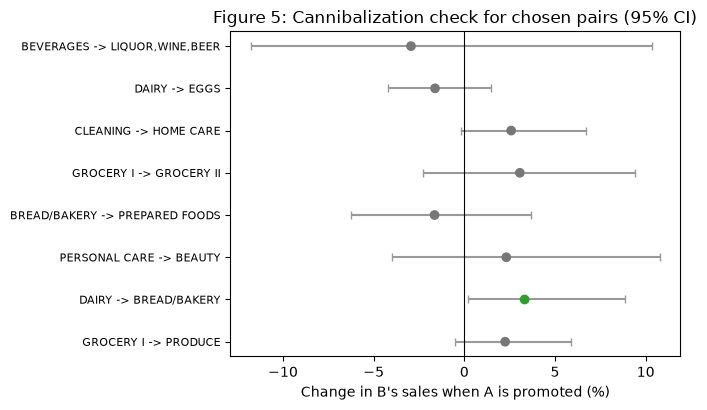

In [16]:
labels = []
for i in range(len(pairs)):
    labels.append(pairs['promoted (A)'].iloc[i] + ' -> ' + pairs['affected (B)'].iloc[i])

ypos = np.arange(len(pairs))[::-1]
low_error = pairs['adj_pct'] - pairs['adj_low']
high_error = pairs['adj_high'] - pairs['adj_pct']

colors = []
for v in pairs['verdict']:
    if v == 'cannibalization':
        colors.append('#d62728')
    elif v == 'halo (positive)':
        colors.append('#2ca02c')
    else:
        colors.append('#777777')

plt.figure(figsize=(7, 4.2))
plt.errorbar(pairs['adj_pct'], ypos, xerr=[low_error, high_error], fmt='none', ecolor='#999999', capsize=3)
plt.scatter(pairs['adj_pct'], ypos, c=colors, zorder=3)
plt.axvline(0, color='black', linewidth=0.8)
plt.yticks(ypos, labels, fontsize=8)
plt.xlabel("Change in B's sales when A is promoted (%)")
plt.title('Figure 5: Cannibalization check for chosen pairs (95% CI)')
plt.tight_layout()
plt.savefig(fig_folder + '/fig5_chosen_pairs.png')
plt.show()

Now we test all pairs with enough data (162 pairs). Since we test many pairs, some can look significant by luck, so we correct the p-values (Benjamini-Hochberg). 5 pairs are significant and all of them are positive, so no cannibalization was found.

In [17]:
# all pairs
rows = []
for fam_a in families:
    for fam_b in families:
        if fam_a == fam_b:
            continue
        events = get_pair_events(fam_a, fam_b)
        if len(events) < 100 or events['week'].nunique() < 15:
            continue
        r = get_lift(events, boot=1000)
        r['A'] = fam_a
        r['B'] = fam_b
        rows.append(r)

screen = pd.DataFrame(rows)
screen = screen.sort_values('p_value').reset_index(drop=True)

m = len(screen)
corrected = []
for i in range(m):
    corrected.append(screen['p_value'].iloc[i] * m / (i + 1))
for i in range(m - 2, -1, -1):
    if corrected[i] > corrected[i + 1]:
        corrected[i] = corrected[i + 1]
screen['p_bh'] = np.minimum(corrected, 1)

significant = screen[screen['p_bh'] < 0.05]
print('pairs tested:', m)
print('clearly significant after correction:', len(significant))
print('pairs with a negative estimate:', (screen['adj_pct'] < 0).sum(), '| positive:', (screen['adj_pct'] > 0).sum())
significant[['A', 'B', 'n', 'adj_pct', 'adj_low', 'adj_high', 'p_bh']].round(3)

pairs tested: 162
clearly significant after correction: 5
pairs with a negative estimate: 54 | positive: 108


,A,B,n,adj_pct,adj_low,adj_high,p_bh
0,BEVERAGES,MAGAZINES,334,13.118,5.604,21.511,0.032
1,CLEANING,DAIRY,195,4.805,2.155,7.128,0.032
2,GROCERY I,DAIRY,251,3.551,1.443,7.199,0.032
3,MEATS,GROCERY II,102,15.906,2.650,44.247,0.032
4,PERSONAL CARE,GROCERY II,211,18.140,6.088,32.835,0.032


Figure 6: each cell shows the change in family B (column) when family A (row) has a surge. Red means B goes down, blue means B goes up, and * means significant.

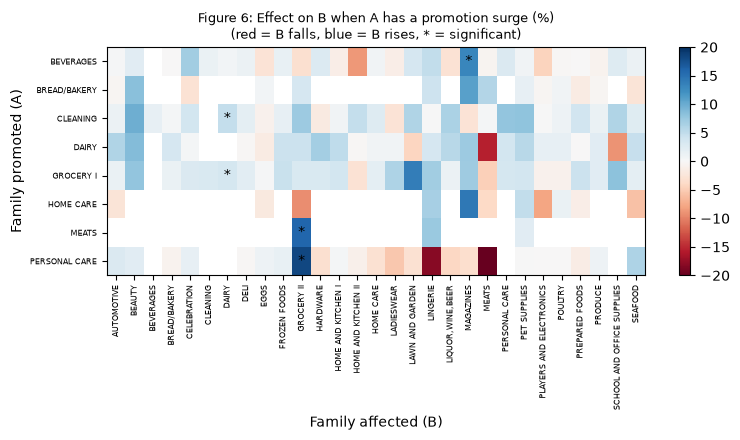

In [18]:
rows_used = sorted(screen['A'].unique())
cols_used = sorted(screen['B'].unique())
matrix = pd.DataFrame(np.nan, index=rows_used, columns=cols_used)
for i in range(len(screen)):
    matrix.loc[screen['A'].iloc[i], screen['B'].iloc[i]] = screen['adj_pct'].iloc[i]

plt.figure(figsize=(8, 4.5))
plt.imshow(matrix.values, cmap='RdBu', vmin=-20, vmax=20, aspect='auto')
plt.xticks(range(len(cols_used)), cols_used, rotation=90, fontsize=6)
plt.yticks(range(len(rows_used)), rows_used, fontsize=6)

for i in range(len(significant)):
    a = significant['A'].iloc[i]
    b = significant['B'].iloc[i]
    plt.text(cols_used.index(b), rows_used.index(a), '*', ha='center', va='center', fontsize=10)

plt.xlabel('Family affected (B)')
plt.ylabel('Family promoted (A)')
plt.title('Figure 6: Effect on B when A has a promotion surge (%)\n(red = B falls, blue = B rises, * = significant)', fontsize=9)
plt.colorbar()
plt.tight_layout()
plt.savefig(fig_folder + '/fig6_all_pairs_heatmap.png')
plt.show()

We save all result tables and figures so they can be used in the report.

In [19]:
# save tables
by_family_a.to_csv(table_folder + '/lift_by_family_launch.csv')
by_family_b.to_csv(table_folder + '/lift_by_family_weekly.csv')
pairs.to_csv(table_folder + '/cannibalization_chosen_pairs.csv', index=False)
screen.to_csv(table_folder + '/cannibalization_all_pairs.csv', index=False)
sensitivity.to_csv(table_folder + '/lift_sensitivity.csv', index=False)
print('tables saved in', table_folder)
print('figures saved in', fig_folder)

tables saved in ../outputs/tables
figures saved in ../outputs/figures_promo


Summary: promotions bring a small real lift of about 4%, and the naive comparison makes it look bigger. Longer promotions give more lift. We did not find cannibalization between families. Limits: a product here is a whole family, and onpromotion is only a count of items, so we cannot measure discount size.